# Лабораторная 5. Пространственная и частотная фильтрация

В этой работе сгладим изображение, подчеркнём границы и осветлим тёмные детали. В первой части применим фильтры к фотографии двумя способами. Во второй соберём из нескольких операций обработку снимка скелета.

## Карта темы

Пиксель в оттенках серого хранит одно число. Раньше мы работали с этими числами напрямую, например сравнивали яркость каждого пикселя с порогом. Чтобы найти границу, нужно сравнить яркость соседних пикселей. Фильтр делает это по одним и тем же правилам на всём изображении.

- Пространство → яркости соседей → сглаживание Гауссом и повышение резкости.
- Частоты → спектр Фурье → те же задачи через ослабление или усиление колебаний яркости.
- Снимок скелета → Лапласиан и Собел → избирательное усиление деталей → гамма-коррекция.

Разбор следует [заданию](../task-text.md) и [решению на marimo](../KZ_Lab5.py). Выводы ячеек сохранены. Чтобы пересчитать их, запусти все ячейки сверху вниз в ядре Python с NumPy, OpenCV и Matplotlib. Оба JPEG лежат в папке `Lab5`.

## Подготовка

NumPy нужен для массивов и преобразования Фурье, OpenCV читает изображения и применяет фильтры, Matplotlib показывает результат. Путь к данным ищем из папки ноутбука, папки лабораторной или корня репозитория.

`load_image` читает байты JPEG и декодирует их через OpenCV. Так путь с русскими буквами обрабатывается средствами Python и NumPy. `show_row` рисует все изображения на шкале от $0$ до $255$. По этой шкале можно сравнивать яркости на снимках, потому что один уровень серого везде означает одно число. В этой ячейке выводятся только имена файлов.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

photo_name = "image.jpg"
skeleton_name = "Fig0343(a)(skeleton_orig).jpg"
here = Path.cwd()
candidates = (here, here.parent, here / "computer-vision" / "sfedu" / "Lab5")
lab_dir = next(
    (folder for folder in candidates
     if (folder / photo_name).is_file() and (folder / skeleton_name).is_file()),
    None,
)
if lab_dir is None:
    raise FileNotFoundError("Открой ноутбук из папки Lab5/explanation или из корня репозитория.")


def load_image(filename, mode):
    data = np.fromfile(lab_dir / filename, dtype=np.uint8)
    image = cv2.imdecode(data, mode)
    if image is None:
        raise ValueError(f"Не удалось прочитать {filename}")
    return image


def show_row(panels, height=4):
    fig, axes = plt.subplots(
        1, len(panels), figsize=(3 * len(panels), height), squeeze=False,
        layout="constrained",
    )
    for ax, (image, title) in zip(axes[0], panels):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.show()


print(f"Файлы найдены. {photo_name}, {skeleton_name}")

Файлы найдены. image.jpg, Fig0343(a)(skeleton_orig).jpg


## Часть 1. Фильтрация фотографии

### Изображение как таблица яркостей

Считываем цветное фото. В цветном массиве у каждой точки есть три числа. OpenCV здесь хранит их в порядке синий, зелёный, красный (`BGR`). После `cvtColor` у точки остаётся одно число яркости, поэтому на ней можно показать все фильтры из задания. `shape` даёт размеры массива, `dtype` показывает, как хранятся числа.

Цветной массив (981, 736, 3)
Полутоновый массив (981, 736), тип uint8
Яркости от 0 до 255, средняя 74.40


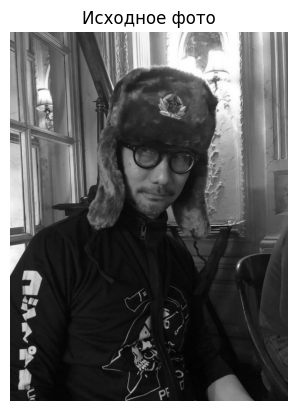

In [2]:
image = load_image(photo_name, cv2.IMREAD_COLOR)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print(f"Цветной массив {image.shape}")
print(f"Полутоновый массив {gray.shape}, тип {gray.dtype}")
print(f"Яркости от {gray.min()} до {gray.max()}, средняя {gray.mean():.2f}")
show_row([(gray, "Исходное фото")])

В форме `(981, 736, 3)` первое число означает строки, второе столбцы, третье цветовые каналы. Форма `(981, 736)` означает по одной яркости на пиксель. Тип `uint8` хранит целые от $0$ до $255$, где $0$ соответствует чёрному, $255$ белому. Исходное фото будет точкой отсчёта для сравнения всех фильтров.

### Задание 1. Ядро Гаусса

Ядро представляет собой таблицу весов. Чтобы получить новую яркость, ставим центр ядра на нужный пиксель, умножаем каждую яркость в окне на её вес и складываем произведения. Затем сдвигаем окно. Гаусс даёт больший вес близким соседям, поэтому усреднение смягчает границу.

Возьмём окно над границей между тёмным слева и светлым справа. Для примера используем маленькое ядро с целыми числителями.

$$
\frac{1}{16}
\begin{bmatrix}
1 & 2 & 1\\
2 & 4 & 2\\
1 & 2 & 1
\end{bmatrix},
\qquad
\begin{bmatrix}
10 & 10 & 50\\
10 & 10 & 50\\
10 & 10 & 50
\end{bmatrix}
$$

Взвешенные суммы по строкам равны $80$, $160$ и $80$. Новая яркость центрального пикселя равна $(80+160+80)/16=20$. На светлой стороне в соседнем окне получится $40$. Перепад между соседними пикселями сократился с $50-10=40$ до $40-20=20$.

В общем виде для радиуса $r$ получаем

$$
g[i,j]=\sum_{a=-r}^{r}\sum_{b=-r}^{r} w[a,b] f[i+a,j+b].
$$

$f$ хранит исходные яркости, $g$ результат. $i,j$ задают нужный пиксель, $a,b$ смещения по строке и столбцу, $w[a,b]$ вес этого соседа. Раскрыть суммы означает выписать одно произведение на каждую клетку окна. `filter2D` делает корреляцию, то есть использует веса в показанном порядке. У симметричных ядер Гаусса, резкости и Лапласиана поворот ядра на $180^\circ$ сохраняет веса, поэтому для них корреляция совпадает со свёрткой.

В самой лабораторной веса берём из функции Гаусса. На расстоянии $\sqrt{x^2+y^2}$ от центра сырой вес равен $\exp(-(x^2+y^2)/(2\sigma^2))$. Чем больше $\sigma$ (сигма), тем медленнее вес убывает с расстоянием. Берём окно радиуса $r=\lceil3\sigma\rceil$ и делим веса на их сумму. Тогда однотонная область с яркостью $c$ после фильтра остаётся яркостью $c\cdot1=c$.

Ячейка строит ядро при $\sigma=1$ и сравнивает его с OpenCV. `meshgrid` создаёт таблицы координат для всех клеток. `getGaussianKernel` даёт столбец весов, а `g_cv @ g_cv.T` умножает его на строку и собирает двумерное ядро.

In [3]:
def gaussian_kernel(sigma):
    radius = int(np.ceil(3 * sigma))
    x = np.arange(-radius, radius + 1)
    X, Y = np.meshgrid(x, x)
    weights = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
    return weights / weights.sum()


G1 = gaussian_kernel(1)
g_cv = cv2.getGaussianKernel(7, 1)
print(np.round(G1, 4))
print(f"Размер {G1.shape}, сумма весов {G1.sum():.8f}")
print(f"Совпадение с OpenCV: {np.allclose(G1, g_cv @ g_cv.T)}")

[[0.     0.0002 0.0011 0.0018 0.0011 0.0002 0.    ]
 [0.0002 0.0029 0.0131 0.0216 0.0131 0.0029 0.0002]
 [0.0011 0.0131 0.0586 0.0966 0.0586 0.0131 0.0011]
 [0.0018 0.0216 0.0966 0.1592 0.0966 0.0216 0.0018]
 [0.0011 0.0131 0.0586 0.0966 0.0586 0.0131 0.0011]
 [0.0002 0.0029 0.0131 0.0216 0.0131 0.0029 0.0002]
 [0.     0.0002 0.0011 0.0018 0.0011 0.0002 0.    ]]
Размер (7, 7), сумма весов 1.00000000
Совпадение с OpenCV: True


Получилась матрица $7\times7$, потому что от центра есть три позиции в каждую сторону. Центральный вес около $0.1592$, сосед по горизонтали получает $0.0966$, дальние углы дают вклад меньше $0.0001$. Напечатанные нули по углам получились при округлении для показа. Сумма полного ядра равна $1$ с заданной точностью. `True` означает, что все веса совпали с OpenCV в пределах допуска `allclose`.

### Задание 2. Размытие фотографии

Применяем ядро к одной и той же фотографии с $\sigma=1,3,7$. Это позволяет увидеть влияние $\sigma$ при неизменном входе. `filter2D(gray, -1, ...)` сохраняет тип `uint8`, а около рамки OpenCV отражает изображение, чтобы заполнить часть окна за границей.

σ = 1, ядро 7 × 7
σ = 3, ядро 19 × 19
σ = 7, ядро 43 × 43


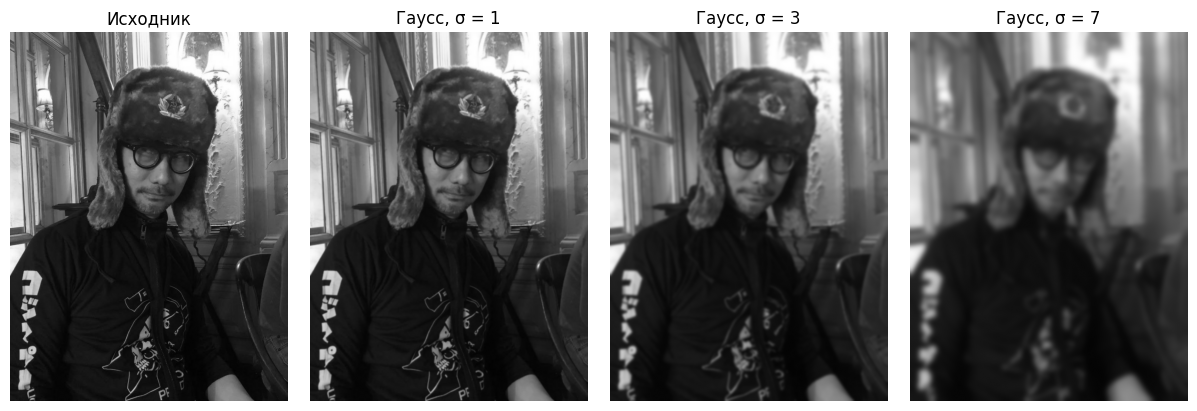

In [4]:
sigmas = (1, 3, 7)
kernels = {sigma: gaussian_kernel(sigma) for sigma in sigmas}
blurred = {
    sigma: cv2.filter2D(gray, -1, kernel)
    for sigma, kernel in kernels.items()
}

for sigma, kernel in kernels.items():
    print(f"σ = {sigma}, ядро {kernel.shape[0]} × {kernel.shape[1]}")

show_row(
    [(gray, "Исходник")]
    + [(blurred[sigma], f"Гаусс, σ = {sigma}") for sigma in sigmas]
)

Окна имеют размеры $7\times7$, $19\times19$ и $43\times43$. При $\sigma=1$ изменения на общем плане небольшие. При $\sigma=7$ мелкая текстура и тонкие линии размылись сильнее, границы стали шире. Вес распределён по большему числу соседей, поэтому отдельный скачок яркости даёт меньший вклад.

### Задание 3. Повышение резкости в пространстве

Даём центральному пикселю вес $5$, четырём соседям сверху, снизу, слева и справа по $-1$. Так новый пиксель равен исходной яркости плюс четыре разности между центром и его соседями. Если вокруг везде $50$, получим $5\cdot50-4\cdot50=50$. На вертикальной границе из примера тёмный пиксель получит $5\cdot10-(3\cdot10+50)=-30$, светлый $5\cdot50-(3\cdot50+10)=90$. После ограничения диапазона у пары будет $0$ и $90$ вместо $10$ и $50$.

Показываем фото целиком и один и тот же фрагмент из строк и столбцов $250$–$549$, чтобы рассмотреть контуры крупнее.

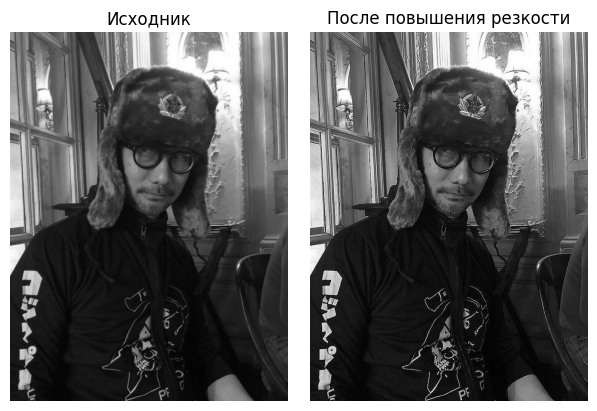

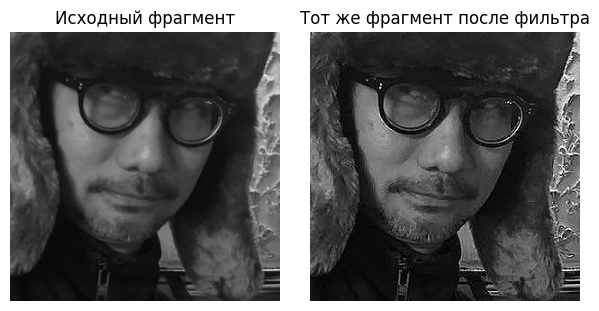

In [5]:
sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0],
])
sharpened = cv2.filter2D(gray, -1, sharpen)
crop = np.s_[250:550, 250:550]

show_row([(gray, "Исходник"), (sharpened, "После повышения резкости")])
show_row(
    [(gray[crop], "Исходный фрагмент"), (sharpened[crop], "Тот же фрагмент после фильтра")],
    height=3,
)

На фрагменте заметнее узкие светлые и тёмные участки вдоль контуров. Ядро увеличило локальный перепад яркости. Оно может усилить мелкий шум или дать светлую и тёмную полосы вдоль резкого края. В выводе яркость ограничена диапазоном $0$–$255$.

### Задание 4. От пикселей к частотам

Представим ряд $[60,40,60,40]$ как сумму постоянной яркости $[50,50,50,50]$ и чередования $[10,-10,10,-10]$. Постоянная часть имеет частоту $0$. Чередование повторяется через два пикселя, его частота по модулю равна $1/2$ колебания на пиксель. На фото плавный переход обычно связан с низкими частотами, мелкая текстура и резкая граница содержат высокие частоты.

Дискретное преобразование Фурье (ДПФ) вычисляет коэффициенты при таких колебаниях. `fft` вычисляет ДПФ для ряда, `fft2` для массива по двум осям. В коэффициенте есть амплитуда (модуль) и фаза, которая задаёт расположение волны. Сумму яркостей можно прочитать в нулевом коэффициенте. Для восстановления изображения нужны полные комплексные коэффициенты.

Сначала проверим это на четырёх яркостях. `fftfreq` печатает частоты в том же порядке, что и `fft`. Обратное преобразование `ifft` собирает ряд из коэффициентов.

In [6]:
row = np.array([60, 40, 60, 40])
row_spectrum = np.fft.fft(row)

print("Частоты в колебаниях на пиксель", np.fft.fftfreq(row.size))
print("Коэффициенты ДПФ", row_spectrum)
print("Восстановленный ряд", np.fft.ifft(row_spectrum).real)

Частоты в колебаниях на пиксель [ 0.    0.25 -0.5  -0.25]
Коэффициенты ДПФ [200.+0.j   0.+0.j  40.+0.j   0.+0.j]
Восстановленный ряд [60. 40. 60. 40.]


Нулевая частота даёт коэффициент $200$, то есть сумму яркостей, а $200/4=50$ даёт их среднее. У самого быстрого чередования коэффициент $40$, он стоит в позиции частоты $-0.5$. На целых координатах колебания $+0.5$ и $-0.5$ дают одну и ту же последовательность $[1,-1,1,-1]$, поэтому NumPy представляет эту частоту один раз. При обратном преобразовании вклад этого коэффициента составляет $40/4=10$ с чередующимся знаком. Вместе с постоянной частью это даёт исходный ряд.

### Спектр фотографии и `fftshift`

У фотографии два направления изменений. `fft2` считает спектр размером с фото, где каждая клетка соответствует паре частот по строкам и по столбцам. Сначала нулевая частота находится в клетке `[0, 0]`. `fftshift` переставляет клетки так, чтобы нулевая частота оказалась в центре и близкие к нулю частоты лежали рядом.

Показываем $20\log_{10}(1+|F|)$ на общей шкале. Модуль берём для просмотра амплитуды. Логарифм сжимает диапазон и помогает увидеть малые амплитуды рядом с большими. Единица под логарифмом даёт значение $0$ для нулевой амплитуды.

Форма спектра (981, 736), центр после fftshift (490, 368)
Нулевой коэффициент 53720416
Коэффициент, делённый на число пикселей: 74.40


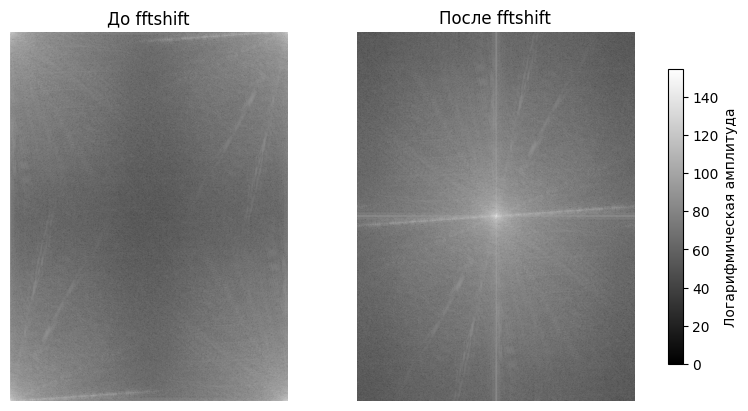

In [7]:
def log_spectrum(spectrum):
    return 20 * np.log10(1 + np.abs(spectrum))


F = np.fft.fft2(gray)
F_shift = np.fft.fftshift(F)
center = tuple(size // 2 for size in gray.shape)
spectrum_max = log_spectrum(F).max()

print(f"Форма спектра {F.shape}, центр после fftshift {center}")
print(f"Нулевой коэффициент {F_shift[center].real:.0f}")
print(f"Коэффициент, делённый на число пикселей: {F_shift[center].real / gray.size:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for ax, (spectrum, title) in zip(
    axes, [(F, "До fftshift"), (F_shift, "После fftshift")],
):
    plot = ax.imshow(log_spectrum(spectrum), cmap="gray", vmin=0, vmax=spectrum_max)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(plot, ax=axes, shrink=0.8, label="Логарифмическая амплитуда")
plt.show()

Самая яркая область переместилась с углов к центру. В центре стоит нулевая частота. Её коэффициент $53\,720\,416$ равен сумме яркостей фото и даёт среднюю яркость около $74.40$ после деления на число пикселей. Рядом с центром видны низкие частоты. Дальше от центра по каждой оси растёт модуль частоты по этой оси. Белая клетка на этом рисунке означает большую амплитуду колебания изображения.

### Подготовка частотной фильтрации

Теорема о свёртке связывает два способа записи фильтра. Пространственной свёртке с периодическими границами соответствует умножение спектра изображения на спектр ядра. Поэтому каждой паре частот можно назначить множитель $H$.

`freq_grid` строит координаты $U,V$ в колебаниях на пиксель, по строкам и столбцам. `apply_filter` умножает исходные комплексные коэффициенты на маску, отменяет `fftshift` и возвращает изображение через `ifft2`. Для вещественного фото и используемых симметричных по частоте масок берём вещественную часть, округляем и ограничиваем значения диапазоном $0$–$255$.

Проверим сборку на маске из единиц. Такая маска сохраняет каждый коэффициент.

In [8]:
def freq_grid(shape):
    u = np.fft.fftshift(np.fft.fftfreq(shape[0]))
    v = np.fft.fftshift(np.fft.fftfreq(shape[1]))
    return np.meshgrid(u, v, indexing="ij")


def to_uint8(image):
    return np.clip(np.round(image), 0, 255).astype(np.uint8)


def apply_filter(F_shift, H):
    G_shift = F_shift * H
    image = np.fft.ifft2(np.fft.ifftshift(G_shift)).real
    return G_shift, to_uint8(image)


def show_filter(G_shift, H, image, title, mask_min, mask_max):
    fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
    spectrum_plot = axes[0].imshow(
        log_spectrum(G_shift), cmap="gray", vmin=0, vmax=spectrum_max,
    )
    axes[0].set_title("Спектр после фильтра")
    mask_plot = axes[1].imshow(H, cmap="gray", vmin=mask_min, vmax=mask_max)
    axes[1].set_title("Маска H")
    axes[2].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[2].set_title("Изображение после сборки")
    for ax in axes:
        ax.axis("off")
    fig.colorbar(spectrum_plot, ax=axes[0], shrink=0.8)
    fig.colorbar(mask_plot, ax=axes[1], shrink=0.8)
    fig.suptitle(title)
    plt.show()


U, V = freq_grid(gray.shape)
_, restored = apply_filter(F_shift, np.ones(gray.shape))
print(f"Маска из единиц вернула исходное фото: {np.array_equal(restored, gray)}")

Маска из единиц вернула исходное фото: True


`True` означает точное совпадение всех пикселей после округления. Теперь можно менять множители и смотреть, как это отражается на фото. В каждой тройке рисунков слева будет амплитуда после умножения, в центре сами множители $H$, справа восстановленные яркости. У спектров общая шкала, у масок своя шкала, указанная справа от каждой маски.

### Задание 5. Низкочастотный фильтр Гаусса (LPF)

Чтобы размыть фото, ослабляем быстрые колебания. В центре маска равна $1$. Дальше от центра множитель плавно падает к нулю. Если расстояние от центра равно $D_0$, множитель $\exp(-1/2)\approx0.61$. Значит, амплитуда такой волны после умножения составит около $61\%$ от исходной.

$$
H(u,v)=\exp\left(-\frac{u^2+v^2}{2D_0^2}\right),
\qquad D_0=\frac{1}{2\pi\sigma}.
$$

$u$ и $v$ задают частоты по двум осям. $u^2+v^2$ задаёт квадрат расстояния до нулевой частоты, а $D_0$ ширину маски в частотах. Формула связи $D_0$ и $\sigma$ получается для пары непрерывных функций Гаусса. Здесь она позволяет подобрать маску, близкую по эффекту к уже применённому конечному ядру. Построим спектр, маску и фото для тех же трёх значений $\sigma$.

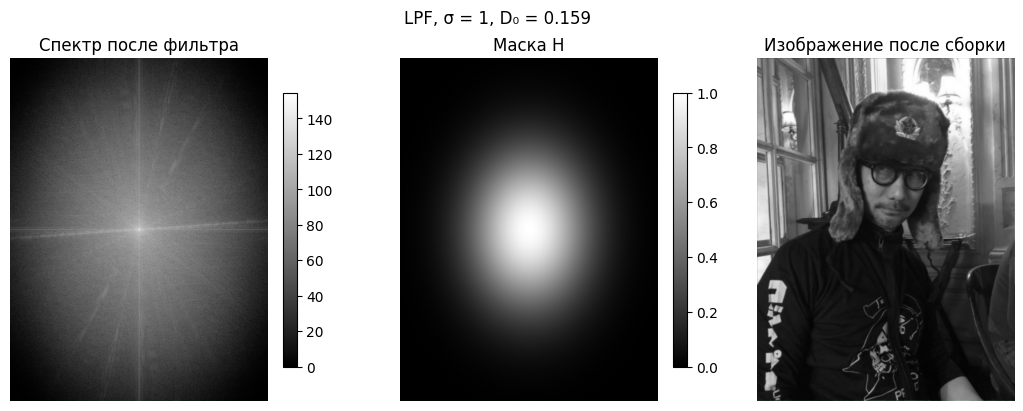

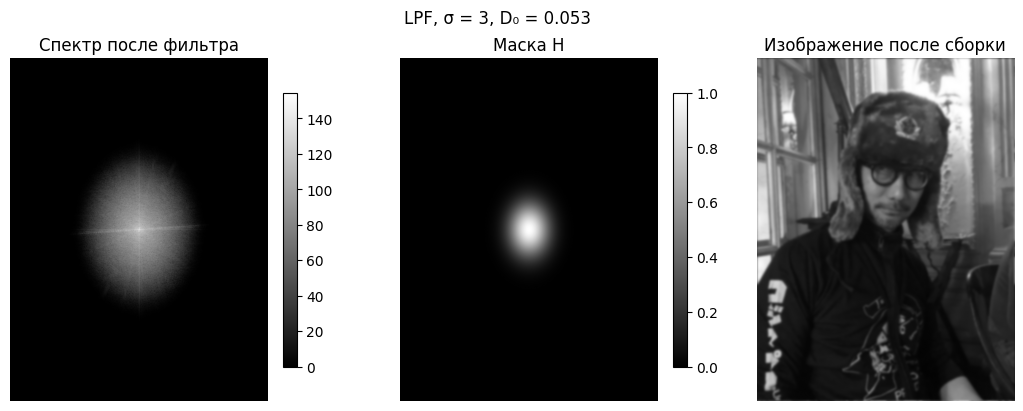

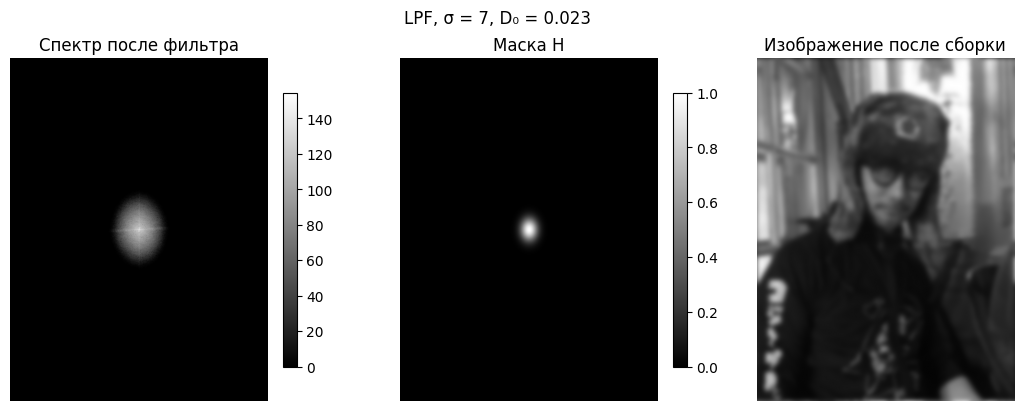

In [9]:
def gaussian_lpf(U, V, sigma):
    D0 = 1 / (2 * np.pi * sigma)
    H = np.exp(-(U**2 + V**2) / (2 * D0**2))
    return D0, H


blurred_freq = {}
for sigma in sigmas:
    D0, H_lpf = gaussian_lpf(U, V, sigma)
    G_lpf, blurred_freq[sigma] = apply_filter(F_shift, H_lpf)
    show_filter(
        G_lpf, H_lpf, blurred_freq[sigma],
        f"LPF, σ = {sigma}, D₀ = {D0:.3f}", 0, 1,
    )

При $\sigma=1$ светлая область маски шире. При $\sigma=7$ $D_0$ уменьшается примерно с $0.159$ до $0.023$, и заметная амплитуда остаётся ближе к центру спектра. На результирующем фото мелкие детали размыты сильнее. Вытянутая по вертикали форма маски связана с размерами фото. По вертикали у нас $981$ отсчёт, по горизонтали $736$ на тот же диапазон частот.

### Проверка двух способов сглаживания

Сравним обе версии при $\sigma=3$. Вычтем яркости после преобразования к знаковому типу `int`, чтобы получить правильные отрицательные разности до взятия модуля. Исключим по $30$ пикселей с каждой стороны. При ДПФ правая граница соседствует с левой и нижняя с верхней. `filter2D` использует отражение, поэтому края считаются иначе. Измерим среднюю и максимальную абсолютные разницы в оставшейся области.

In [10]:
lpf_diff = np.abs(blurred_freq[3].astype(int) - blurred[3].astype(int))
interior_lpf = lpf_diff[30:-30, 30:-30]
print(f"Средняя разница {interior_lpf.mean():.6f}")
print(f"Максимальная разница {interior_lpf.max()}")

Средняя разница 0.023956
Максимальная разница 1


Средняя разница около $0.024$ уровня яркости, максимальная $1$. Внутри фото результаты почти совпали. Пространственное ядро обрезано до окна $19\times19$. Частотная маска построена по формуле для Гаусса, и выход каждого способа округляется до целых яркостей.

### Задание 6. Усиление высоких частот (HFE)

Для резкости хотим сохранить постоянную составляющую и увеличить амплитуды быстрых колебаний. В задании маска имеет вид

$$
H(u,v)=5-2\cos(2\pi u)-2\cos(2\pi v).
$$

- При $(u,v)=(0,0)$ оба косинуса равны $1$, множитель равен $1$.
- При $(u,v)=(-0.5,0)$ косинусы равны $-1$ и $1$, множитель равен $5$.
- При приближении к $-0.5$ вдоль обеих осей множитель приближается к $9$.

Формула связана с ядром резкости из задания 3. Центр ядра даёт постоянное слагаемое $5$. У пары соседей по первой оси веса $-1$ и сдвиги на один пиксель в разные стороны. В спектре им соответствуют члены $-e^{-2\pi i u}$ и $-e^{2\pi i u}$, сумма которых равна $-2\cos(2\pi u)$. Вторая пара даёт $-2\cos(2\pi v)$. Здесь $i$ обозначает мнимую единицу. Применим эту маску и посмотрим диапазон множителей.

Минимум маски 1.000000, максимум 8.999990


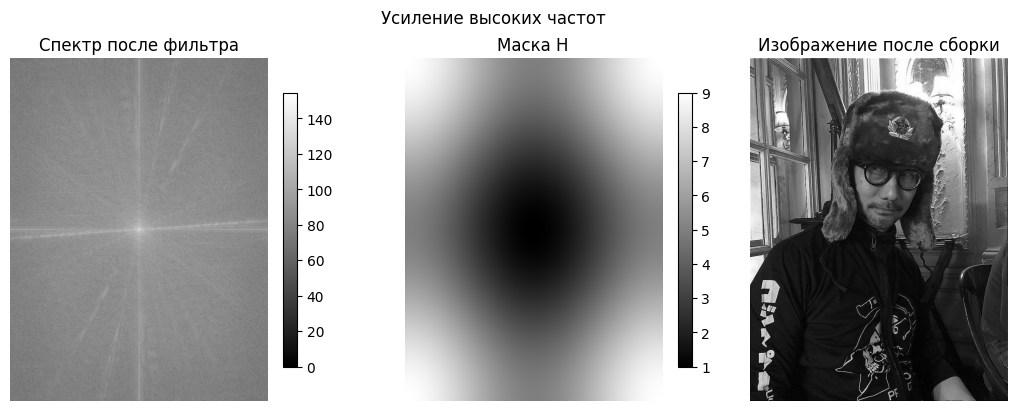

In [11]:
H_hfe = 5 - 2 * np.cos(2 * np.pi * U) - 2 * np.cos(2 * np.pi * V)
G_hfe, sharpened_freq = apply_filter(F_shift, H_hfe)

print(f"Минимум маски {H_hfe.min():.6f}, максимум {H_hfe.max():.6f}")
show_filter(G_hfe, H_hfe, sharpened_freq, "Усиление высоких частот", 1, 9)

Множитель в центре равен $1$, поэтому средняя составляющая сохраняется до округления и ограничения яркостей. Максимум около $8.999990$, потому что по оси с нечётным числом отсчётов сетка лишь приближается к $-0.5$. На маске светлее по краям. На результирующей фотографии контуры подчёркнуты примерно так же, как после пространственного ядра резкости.

### Проверка двух способов повышения резкости

У ядра $3\times3$ радиус один пиксель. Сравним целочисленные яркости внутри рамки шириной один пиксель и посмотрим на тот же фрагмент, что в задании 3. Так проверим, что формула HFE действительно воспроизводит ядро резкости.

Средняя разница 0.0
Максимальная разница 0


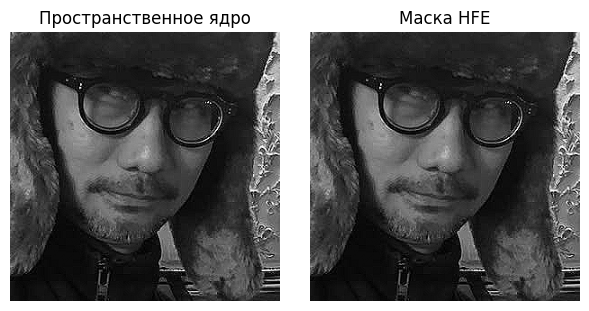

In [12]:
hfe_diff = np.abs(sharpened_freq.astype(int) - sharpened.astype(int))
interior_hfe = hfe_diff[1:-1, 1:-1]
print(f"Средняя разница {interior_hfe.mean():.1f}")
print(f"Максимальная разница {interior_hfe.max()}")
show_row(
    [(sharpened[crop], "Пространственное ядро"), (sharpened_freq[crop], "Маска HFE")],
    height=3,
)

Обе разницы равны $0$. Все внутренние пиксели совпали после перевода в `uint8`. У рамки результат может отличаться из-за отражения в `filter2D` и периодических границ у ДПФ. Именно у HFE совпадение внутри точное, потому что множители выведены из того же конечного ядра. В проверке LPF формула частотного Гаусса давала приближение к конечному ядру.

## Часть 2. Улучшение снимка скелета

### (a) Исходные яркости

На снимке нужно сделать различимыми кости и детали в тёмных областях. Простое усиление перепадов поднимает отклик и на деталях, и на шуме. Поэтому сначала построим вариант с резкостью и отдельно оценим, где яркость меняется на протяжённых участках. Затем объединим эти две карты и осветлим результат.

Загружаем JPEG сразу в оттенках серого. Переводим яркости в `float64` до вычислений. У Лапласиана бывают отрицательные значения, а у градиента бывают значения больше $255$. `float64` хранит оба случая и сохраняет дробные значения при усреднении.

Размер снимка (800, 500), тип для вычислений float64
Яркости от 0 до 255, средняя 17.23


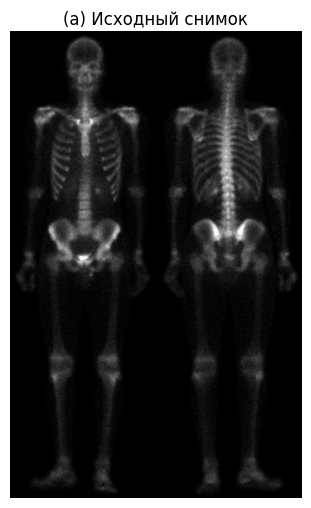

In [13]:
skeleton = load_image(skeleton_name, cv2.IMREAD_GRAYSCALE)
f = skeleton.astype(np.float64)

print(f"Размер снимка {f.shape}, тип для вычислений {f.dtype}")
print(f"Яркости от {skeleton.min()} до {skeleton.max()}, средняя {skeleton.mean():.2f}")
show_row([(skeleton, "(a) Исходный снимок")], height=5)

В массиве $800$ строк и $500$ столбцов. Встречаются значения от $0$ до $255$, но средняя яркость около $17.23$. Большую часть кадра занимает тёмный фон, на котором слабо видны некоторые детали костей. Переход к `float64` изменил способ хранения чисел, сами яркости пока те же.

### (b) Лапласиан

Первая разность показывает, насколько яркость изменилась между соседями. Вторая разность показывает, как изменилась сама первая разность. На переходе $[10,10,50,50]$ первые разности равны $[0,40,0]$, а вторые $[40,-40]$. Вместе знаки показывают, с какой стороны перепада расположен пиксель.

Лапласиан вычисляет аналог второй разности на плоскости. В нашем ядре берём сумму восьми соседей и вычитаем восемь яркостей центра. На ровном участке выходит $0$. На тёмной стороне вертикальной границы из первой части три соседа дают $50$, пять дают $10$, а центр равен $10$. Результат $3\cdot50+5\cdot10-8\cdot10=120$. На светлой стороне при обратном соотношении получается $-120$.

Для показа растягиваем диапазон откликов от минимума до максимума на шкалу $0$–$255$. Для следующего расчёта оставляем исходный массив `lap` со знаками.

Отклик Лапласиана от -228 до 223


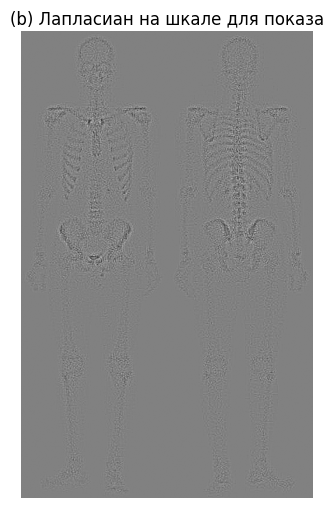

In [14]:
laplacian_kernel = np.array([
    [1,  1, 1],
    [1, -8, 1],
    [1,  1, 1],
])
lap = cv2.filter2D(f, -1, laplacian_kernel)
lap_min, lap_max = lap.min(), lap.max()
lap_display = (
    to_uint8(255 * (lap - lap_min) / (lap_max - lap_min))
    if lap_max > lap_min else np.zeros_like(skeleton)
)

print(f"Отклик Лапласиана от {lap_min:.0f} до {lap_max:.0f}")
show_row([(lap_display, "(b) Лапласиан на шкале для показа")], height=5)

Отклик лежит между $-228$ и $223$. При растяжении на шкалу $0$–$255$ нулю соответствует уровень $129$, поэтому тёмный фон исходника выглядит здесь средне-серым. Светлые и тёмные штрихи показывают знаки и силу отклика. На рисунке видны и контуры, и мелкие точечные отклики.

### (c) Резкость через Лапласиан

Вычитаем Лапласиан из исходного изображения, потому что центр ядра отрицательный. На светлой стороне края из примера вычитаем $-120$ из $50$ и получаем $170$. На тёмной стороне из $10$ вычитаем $120$ и получаем $-110$, после `clip` это $0$. Перепад увеличился.

В формуле `c = f - lap` переменная `c` хранит изображение (c), а `f` хранит исходник (a). Покажем их на одной шкале.

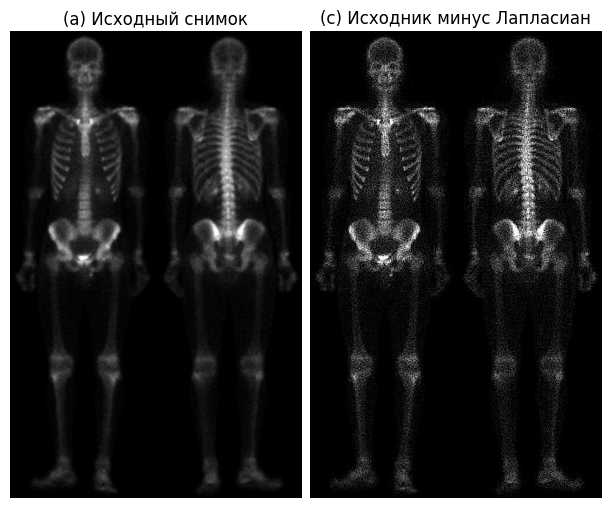

In [15]:
c = np.clip(f - lap, 0, 255)
show_row(
    [(skeleton, "(a) Исходный снимок"), (to_uint8(c), "(c) Исходник минус Лапласиан")],
    height=5,
)

На (c) края выглядят контрастнее, вместе с ними заметнее часть точечных деталей. Полезный эффект виден на контурах. Чтобы управлять вкладом этой картинки, построим карту силы границ.

### (d) Градиент Собела

Градиент измеряет, насколько быстро меняется яркость вдоль каждой оси. Собел для горизонтального изменения сравнивает взвешенные суммы правого и левого столбцов окна $3\times3$. У среднего пикселя каждого столбца вес $2$, у крайних по $1$. Для вертикального изменения так же сравниваются нижняя и верхняя строки.

В окне из первой части правый столбец содержит три числа $50$, левый три числа $10$. Горизонтальный отклик равен $(1+2+1)\cdot50-(1+2+1)\cdot10=160$. Строки одинаковые, поэтому вертикальный отклик равен $0$. В коде `gx` и `gy` хранят эти отклики, а $|g_x|+|g_y|$ служит мерой силы границы без учёта её направления. Модули нужны, чтобы перепады из тёмного в светлое и из светлого в тёмное оба давали положительный вклад.

Максимум силы градиента 574


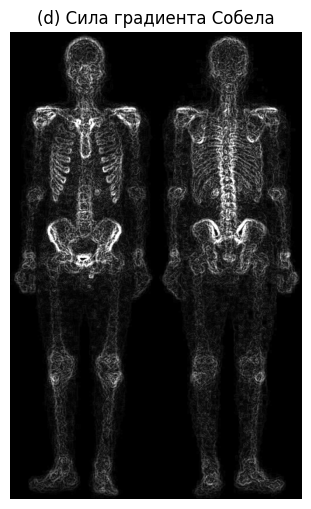

In [16]:
gx = cv2.Sobel(f, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(f, cv2.CV_64F, 0, 1, ksize=3)
grad = np.abs(gx) + np.abs(gy)

print(f"Максимум силы градиента {grad.max():.0f}")
show_row([(to_uint8(grad), "(d) Сила градиента Собела")], height=5)

Светлые линии показывают участки с сильным перепадом яркости. Максимум в массиве равен $574$, поэтому для показа значения выше $255$ ограничены. Для следующего шага передаём полный массив `grad`, чтобы самые сильные отклики сохранили величину.

### (e) Сглаживание градиента

В каждой точке заменяем силу градиента средним из $25$ значений в окне $5\times5$. Одиночный отклик $100$ среди нулей даст среднее $4$. Если отклик $100$ идёт полосой из пяти пикселей, среднее будет $20$. Так отдельный всплеск даёт меньший вклад, чем ряд сильных откликов на границе. Оба массива показываем на одинаковой шкале.

Максимум после сглаживания 376.96


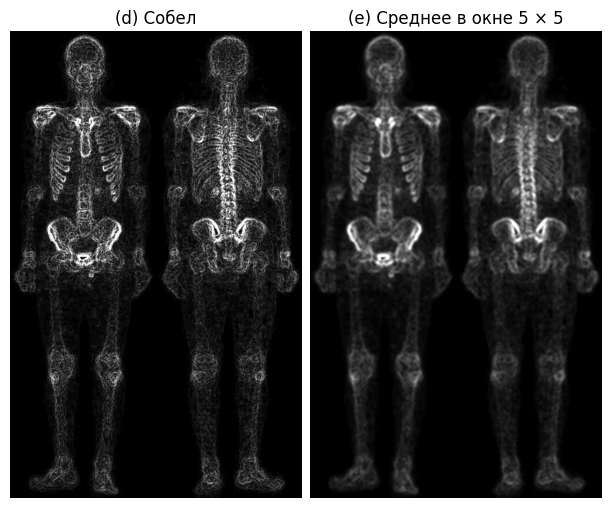

In [17]:
grad_smooth = cv2.blur(grad, (5, 5))

print(f"Максимум после сглаживания {grad_smooth.max():.2f}")
show_row(
    [(to_uint8(grad), "(d) Собел"), (to_uint8(grad_smooth), "(e) Среднее в окне 5 × 5")],
    height=5,
)

Пиковый отклик снизился с $574$ до $376.96$. Яркие линии стали мягче и шире. Теперь карта назначает заметный вес и самим границам, и ближайшим к ним пикселям. На слабых участках вес будет меньше.

### (f) Маска усиления

Делим сглаженный градиент на его максимум. Получаем карту весов от $0$ до $1$. Затем поэлементно умножаем на неё резкое изображение (c). Например, при яркости (c) $100$ и весе $0.1$ добавка получится $10$, а при весе $0.8$ получится $80$. Для однотонного входа максимум может быть нулём. В таком случае вес везде равен нулю.

Буквы на рисунках обозначают шаги из задания. `mask` здесь соответствует рисунку (f) и хранит добавку к яркости, а `f` в коде по-прежнему хранит исходник.

Вес от 0.00 до 1.00
Максимальная добавка 252.24


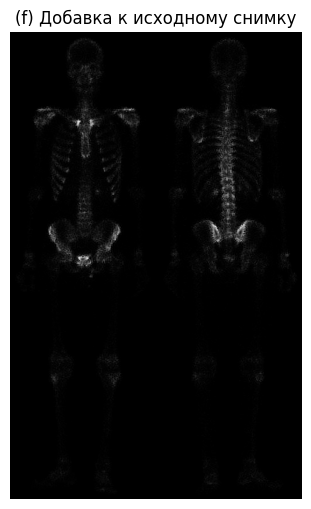

In [18]:
peak = grad_smooth.max()
weights = grad_smooth / peak if peak > 0 else np.zeros_like(grad_smooth)
mask = c * weights

print(f"Вес от {weights.min():.2f} до {weights.max():.2f}")
print(f"Максимальная добавка {mask.max():.2f}")
show_row([(to_uint8(mask), "(f) Добавка к исходному снимку")], height=5)

Вес лежит между $0$ и $1$, максимальная добавка около $252.24$. Светлые части маски совпадают с некоторыми сильными контурами костей. На большей части фона добавка мала. На результат влияют и сила сглаженного градиента, и яркость (c) в той же точке.

### (g) Добавка к исходному снимку

Прибавляем (f) к исходному снимку (a). Там, где маска близка к нулю, яркость почти сохраняется. Там, где маска велика, яркость растёт. Ограничиваем сумму до $255$, чтобы самые яркие значения помещались в изображение.

Средняя яркость после добавки 20.65


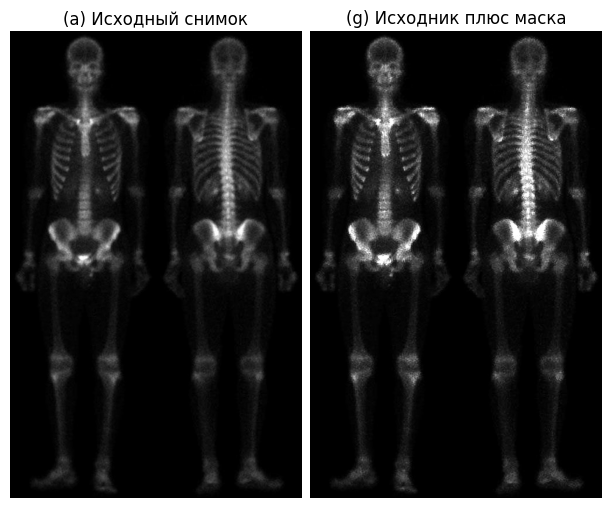

In [19]:
g = np.clip(f + mask, 0, 255)

print(f"Средняя яркость после добавки {g.mean():.2f}")
show_row(
    [(skeleton, "(a) Исходный снимок"), (to_uint8(g), "(g) Исходник плюс маска")],
    height=5,
)

Средняя яркость выросла с $17.23$ до $20.65$. На (g) некоторые контуры и детали костей заметнее, при этом большая часть снимка ещё тёмная. Следующий шаг поднимет яркости в тенях.

### (h) Гамма-коррекция

Делим яркость $r$ на $255$, возводим дробь в степень $\gamma=0.5$ и возвращаемся к шкале $0$–$255$.

$$s=255\left(\frac{r}{255}\right)^{0.5}.$$

Здесь $s$ обозначает новую яркость. Квадратный корень поднимает число между $0$ и $1$. Например, четверть шкалы превращается в половину, поэтому $64$ становится примерно $128$. Чёрная и белая точки остаются на концах шкалы. Преобразование работает с каждой яркостью отдельно.

Средняя яркость до гаммы 20.65, после 47.45


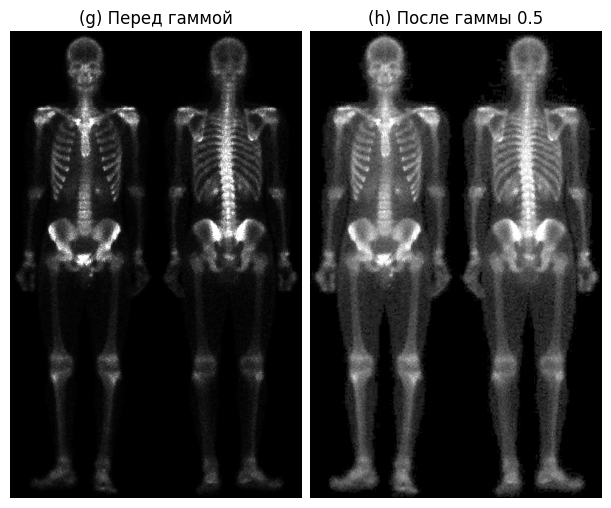

In [20]:
gamma = 0.5
h = 255 * (g / 255) ** gamma
result = to_uint8(h)

print(f"Средняя яркость до гаммы {g.mean():.2f}, после {h.mean():.2f}")
show_row(
    [(to_uint8(g), "(g) Перед гаммой"), (result, "(h) После гаммы 0.5")],
    height=5,
)

Средняя яркость выросла с $20.65$ до $47.45$ до округления. Слабые полутона стали виднее. Гамма-коррекция может осветлить и фоновые точки, поскольку применяет одну формулу ко всем пикселям.

### Сравнение исходника и результата

Ставим (a) рядом с (h) на одной шкале. Сравним, насколько хорошо различимы границы костей и сколько деталей видно в тёмных участках.

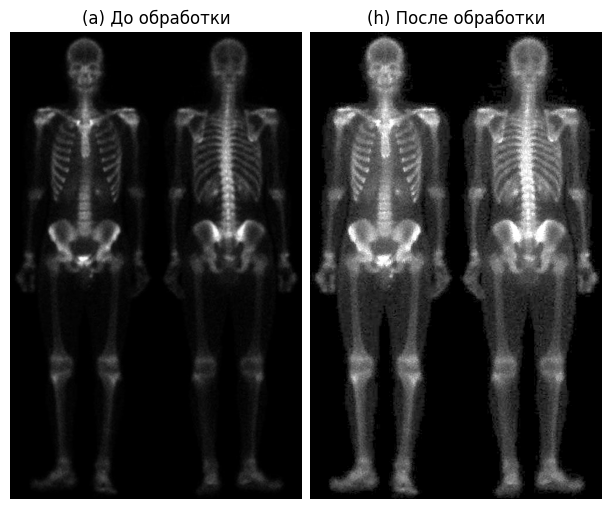

In [21]:
show_row(
    [(skeleton, "(a) До обработки"), (result, "(h) После обработки")],
    height=6,
)

На итоговом снимке лучше различимы рёбра, позвоночник и контуры таза. Маска подняла яркость в областях с сильными перепадами, гамма сделала светлее оставшиеся тёмные полутона. Фон местами тоже стал светлее.

## Короткие ответы для защиты

| Что могут спросить | Что объяснить |
| --- | --- |
| Зачем нормировать ядро Гаусса? | При сумме весов $1$ однотонная область сохраняет яркость. При большей $\sigma$ веса медленнее убывают от центра. |
| Что показывает `fftshift`? | Он ставит нулевую частоту в центр. Модуль и логарифм нужны для показа спектра. Фильтр умножает комплексные коэффициенты из сдвинутого спектра. |
| Как различаются LPF и HFE? | LPF ослабляет быстрые колебания и размывает фото. HFE усиливает быстрые колебания и повышает резкость. Обе маски равны $1$ на нулевой частоте. |
| Почему сравнивали внутренние пиксели? | У пространственной и частотной фильтрации разные правила продолжения за рамку. HFE даёт то же ядро резкости, поэтому внутри разница $0$. |
| Зачем на снимке и Лапласиан, и Собел? | Лапласиан повышает резкость на шаге (c). Сглаженный Собел задаёт вес, с которым (c) входит в добавку к исходнику. Гамма поднимает тёмные яркости после добавки. |

## Как всё складывается

На границе $10 \to 50$ пространственный Гаусс усредняет стороны, например до $20 \to 40$. Частотный Гаусс даёт похожее сглаживание, потому что ослабляет быстрые колебания, из которых складывается резкий переход. Ядро резкости увеличивает перепад до $0 \to 90$ после ограничения диапазона. Его частотная запись даёт маску HFE. В снимке скелета к идее повышения резкости добавляется карта границ, которая управляет весом усиления в каждой точке.

Дальше эти операции пригодятся при поиске границ. Например, в детекторе Canny сглаживание уменьшает влияние шума перед вычислением градиента.

## Проверь себя

1. Вся окрестность имеет яркость $40$. Что вернёт нормированное ядро Гаусса, а что ядро резкости из задания 3?

<details>
<summary>Ответ</summary>

Оба вернут $40$. У Гаусса сумма весов равна $1$. У ядра резкости $5\cdot40-4\cdot40=40$.

</details>

2. Что изменится, если увеличить $\sigma$ с $3$ до $7$ в пространственном фильтре и в LPF?

<details>
<summary>Ответ</summary>

Пространственное ядро вырастет с $19\times19$ до $43\times43$. В спектре $D_0$ упадёт с $0.053$ до $0.023$. Оба способа дадут более сильное размытие.

</details>

3. Что будет, если подставить в формулу HFE номера строк и столбцов вместо частот из `fftfreq`?

<details>
<summary>Ответ</summary>

У целых $u,v$ оба косинуса равны $1$. Маска станет $5-2-2=1$ во всех клетках. Умножение на неё сохранит исходный спектр.

</details>

4. На исходнике яркость пикселя $20$, на (c) яркость $100$. Что получится на шаге (g) при весе $0.05$ и при весе $0.8$?

<details>
<summary>Ответ</summary>

При весе $0.05$ добавка равна $100\cdot0.05=5$, результат $25$. При весе $0.8$ добавка равна $80$, результат $100$. Так карта границ определяет, насколько сильно изменится точка.

</details>

5. Почему при отрицательном центре ядра мы вычисляем `f - lap`? Проверь на яркости $50$ с откликом $-120$.

<details>
<summary>Ответ</summary>

У светлого пикселя с более тёмными соседями отклик отрицательный. Вычитание даёт $50-(-120)=170$ и усиливает светлую сторону края. При сложении получилось бы $-70$ до ограничения диапазона.

</details>